# Part 1: Data Preparation and Exploration
**MGSC 661, Group 12: Predicting next-hour net bike loss at Capital Bikeshare stations**

This notebook builds the shared dataset that the rest of the team uses for modelling:

1. Load one month per season of Capital Bikeshare trip files: **January, May, August and October 2026**
2. Check missing values and data quality, then clean
3. Aggregate trips into **station-hour** rows (departures, arrivals, net flow)
4. Build the target: **next-hour net bike loss** = departures minus arrivals in the following hour
5. Add features: lagged net flow, calendar, weather, station capacity
6. Create **chronological** train / validation / test splits **inside each month**, so every season appears in all three
7. Exploratory charts: demand by hour, by weekday, and by weather

**Output:** `output/station_hour_{train,val,test}.csv.gz`, shared with Parts 2 to 4.

## 0. Setup

In [1]:
import glob, io, os, zipfile, urllib.request, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.tseries.holiday import USFederalHolidayCalendar

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False})

### Configuration
Put the monthly CSVs (or zips) in `DATA_DIR`. Set `DOWNLOAD = True` to fetch the 4 zips (about 90 MB) from the Capital Bikeshare S3 bucket automatically.

**Why split inside each month?** The 4 months are not consecutive. A plain time split would make October the entire test set, so the model would train on 3 seasons and be tested on a different one. Instead, every month is split the same way by day:

| Days of each month | Use |
|---|---|
| 1 to 7 | Only used to build the one-week lag (dropped) |
| 8 to 21 | Train |
| 22 to 25 | Validation |
| 26 to end | Test |

In [2]:
DATA_DIR = "."             # CSVs sit in the same folder as the notebook
OUT_DIR = "output"

MONTHS = ["202601", "202605", "202608", "202610"]   # winter, spring, summer, fall

N_STATIONS = 100

TRAIN_LAST_DAY = 21
VAL_LAST_DAY = 25

SEASON = {1: "winter", 5: "spring", 8: "summer", 10: "fall"}

def split_of(ts):
    d = ts.dt.day
    return np.select([d <= TRAIN_LAST_DAY, d <= VAL_LAST_DAY], ["train", "val"], "test")

DC_LAT, DC_LON = 38.9072, -77.0369
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Load the trip data

In [3]:
files = [os.path.join(DATA_DIR, f"{m}-capitalbikeshare-tripdata.csv") for m in MONTHS]
trips = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
trips["started_at"] = pd.to_datetime(trips["started_at"], format="mixed")
trips["ended_at"] = pd.to_datetime(trips["ended_at"], format="mixed")
print(f"{len(files)} files, {len(trips):,} trips")
trips.head()

4 files, 2,176,592 trips


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,03FA2293C051163C,classic_bike,2026-01-04 15:56:26.146,2026-01-04 16:02:56.393,8th & K St NE,31660.0,New York Ave & Hecht Ave NE,31518.0,38.902594,-76.995141,38.915604,-76.983683,member
1,01C478AD5DD27444,electric_bike,2026-01-17 15:12:11.912,2026-01-17 15:17:58.238,8th & K St NE,31660.0,New York Ave & Hecht Ave NE,31518.0,38.902594,-76.995141,38.915604,-76.983683,member
2,064CCCADB41E193C,electric_bike,2026-01-13 21:17:51.779,2026-01-13 21:21:45.187,Georgia Ave & Dahlia St NW,31425.0,Takoma Metro,31408.0,38.976061,-77.026747,38.975219,-77.016855,member
3,4C990F7ED7C1D93A,electric_bike,2026-01-07 21:11:24.346,2026-01-07 21:15:32.600,Georgia Ave & Dahlia St NW,31425.0,Takoma Metro,31408.0,38.976061,-77.026747,38.975219,-77.016855,member
4,DACE615CE7D9E441,electric_bike,2026-01-16 08:54:26.216,2026-01-16 09:01:43.052,2nd St & Seaton Pl NE,31522.0,John McCormack Rd & Michigan Ave NE,31502.0,38.914751,-77.003560,38.934600,-76.995500,member


## 2. Missing values and data quality

In [4]:
missing = trips.isna().mean().mul(100).round(1).rename("% missing")
missing.to_frame()

,% missing
ride_id,0.0
rideable_type,0.0
started_at,0.0
ended_at,0.0
start_station_name,14.5
start_station_id,14.5
end_station_name,15.4
end_station_id,15.4
start_lat,0.0
start_lng,0.0


In [5]:
# Are the trips without a station all e-bikes (parked outside a dock)?
no_station = trips["start_station_id"].isna() | trips["end_station_id"].isna()
print(f"trips missing a start or end station: {no_station.mean():.1%}")
print(trips.loc[no_station, "rideable_type"].value_counts(normalize=True).round(3))

trips missing a start or end station: 24.3%
rideable_type
electric_bike    0.998
classic_bike     0.002
Name: proportion, dtype: float64


In [6]:
trips["duration_min"] = (trips["ended_at"] - trips["started_at"]).dt.total_seconds() / 60
print(trips["duration_min"].describe().round(1))
print("zero or negative duration:", (trips["duration_min"] <= 0).sum())
print("longer than 24 hours:     ", (trips["duration_min"] > 24 * 60).sum())

count    2176592.0
mean          13.3
std           42.2
min            0.0
25%            5.2
50%            8.6
75%           14.3
max         1500.4
Name: duration_min, dtype: float64
zero or negative duration: 0
longer than 24 hours:      1276


### Cleaning rules
- **Drop trips with no start or end station.** These are dockless e-bike trips and do not move bikes between docks in the same way.
- **Drop trips with duration ≤ 0 or > 24 hours** (clock errors or bikes that were never returned properly).
- **Keep only trips that start inside one of the 4 study months.** Each monthly file contains a few trips from the previous month.

In [7]:
n0 = len(trips)
loaded = [os.path.basename(f)[:6] for f in files]   # only months whose file was found
periods = [pd.Period(m, "M") for m in loaded]
start, end = periods[0].start_time, periods[-1].end_time

clean = trips[
    ~no_station
    & trips["duration_min"].between(0, 24 * 60, inclusive="right")
    & trips["started_at"].dt.to_period("M").isin(periods)
].copy()

clean["start_station_id"] = clean["start_station_id"].astype("int64")
clean["end_station_id"] = clean["end_station_id"].astype("int64")
print(f"kept {len(clean):,} of {n0:,} trips ({len(clean)/n0:.1%}); removed {n0-len(clean):,}")

kept 1,646,866 of 2,176,592 trips (75.7%); removed 529,726


## 3. Aggregate to station-hour
Departures are counted at the start station in the hour the trip starts; arrivals at the end station in the hour it ends.

In [8]:
clean["start_hour"] = clean["started_at"].dt.floor("h")
clean["end_hour"] = clean["ended_at"].dt.floor("h")
clean["is_casual"] = (clean["member_casual"] == "casual").astype(int)
clean["is_ebike"] = (clean["rideable_type"] == "electric_bike").astype(int)

dep = (clean.groupby(["start_station_id", "start_hour"])
       .agg(departures=("ride_id", "size"),
            casual_dep=("is_casual", "sum"),
            ebike_dep=("is_ebike", "sum"))
       .rename_axis(["station_id", "hour"]))
arr = (clean.groupby(["end_station_id", "end_hour"]).size()
       .rename("arrivals").rename_axis(["station_id", "hour"]))

### Choose the busiest stations
To keep the dataset manageable, we model the `N_STATIONS` busiest stations. They are chosen using **training days only**, so the test days do not influence which stations we study.

In [9]:
train_mask = lambda idx: split_of(idx.get_level_values("hour").to_series()) == "train"
activity = (dep.loc[train_mask(dep.index), "departures"].groupby("station_id").sum()
            .add(arr.loc[train_mask(arr.index)].groupby("station_id").sum(), fill_value=0)
            .sort_values(ascending=False))
top_ids = activity.head(N_STATIONS).index
print(f"top {N_STATIONS} of {len(activity)} stations carry {activity.head(N_STATIONS).sum()/activity.sum():.1%} of training-period activity")

top 100 of 876 stations carry 46.1% of training-period activity


Build a **complete** grid (every station × every hour of the 4 months, zeros included). Without the zero rows, lag features would skip hours and be wrong.

In [10]:
hours = pd.DatetimeIndex(np.concatenate([
    pd.date_range(p.start_time, p.end_time.floor("h"), freq="h") for p in periods]))
grid = pd.MultiIndex.from_product([top_ids, hours], names=["station_id", "hour"])

sh = (pd.DataFrame(index=grid)
      .join(dep).join(arr)
      .fillna(0).astype(int)
      .reset_index()
      .sort_values(["station_id", "hour"]))
sh["net_loss"] = sh["departures"] - sh["arrivals"]          # >0 means the station lost bikes this hour
sh["casual_share"] = (sh["casual_dep"] / sh["departures"]).fillna(0)
sh["ebike_share"] = (sh["ebike_dep"] / sh["departures"]).fillna(0)
sh = sh.drop(columns=["casual_dep", "ebike_dep"])
sh["month_key"] = sh["hour"].dt.to_period("M").astype(str)
sh["season"] = sh["hour"].dt.month.map(SEASON)
print(f"{len(sh):,} station-hour rows ({len(top_ids)} stations x {len(hours):,} hours)")
print(f"share of station-hours with no trips: {((sh.departures == 0) & (sh.arrivals == 0)).mean():.1%}")

297,600 station-hour rows (100 stations x 2,976 hours)
share of station-hours with no trips: 25.6%


## 4. Target and lag features
All shifts are done **within each station and month**, so a lag never reaches across the gap between two months.

In [11]:
g = sh.groupby(["station_id", "month_key"])["net_loss"]

# TARGET: net bike loss in the NEXT hour
sh["target_next_net_loss"] = g.shift(-1)

# Lags: what happened recently at this station (all known at prediction time)
sh["net_lag0"] = sh["net_loss"]            # current hour
sh["net_lag1"] = g.shift(1)
sh["net_lag2"] = g.shift(2)
sh["net_lag3"] = g.shift(3)
sh["net_sum_3h"] = sh["net_lag0"] + sh["net_lag1"] + sh["net_lag2"]
sh["net_lag_1w"] = g.shift(168 - 1)        # same hour as the TARGET hour, one week earlier
sh["dep_lag_1w"] = sh.groupby(["station_id", "month_key"])["departures"].shift(168 - 1)

### Historical-average baseline (for Part 2)
Average net loss for each station × weekday × hour, computed on **training data only** and attached to every row. This is the baseline the models must beat.

In [12]:
sh["target_hour"] = sh["hour"] + pd.Timedelta(hours=1)
sh["t_dow"] = sh["target_hour"].dt.dayofweek
sh["t_hod"] = sh["target_hour"].dt.hour

hist = (sh[(split_of(sh["target_hour"]) == "train") & sh["net_lag_1w"].notna()]
        .groupby(["station_id", "t_dow", "t_hod"])["target_next_net_loss"].mean()
        .rename("baseline_hist_avg"))
sh = sh.join(hist, on=["station_id", "t_dow", "t_hod"])

## 5. Calendar, station and weather features

In [13]:
holidays = USFederalHolidayCalendar().holidays(start, end)
sh["hour_of_day"] = sh["t_hod"]                  # calendar features describe the TARGET hour
sh["day_of_week"] = sh["t_dow"]
sh["is_weekend"] = (sh["t_dow"] >= 5).astype(int)
sh["is_holiday"] = sh["target_hour"].dt.normalize().isin(holidays).astype(int)
sh["month"] = sh["target_hour"].dt.month
sh = sh.drop(columns=["t_dow", "t_hod"])

**Station information** from the live GBFS feed: coordinates and capacity (number of docks). Trip files use the short station number, which matches the feed's `short_name`.

In [14]:
try:
    url = "https://gbfs.lyft.com/gbfs/2.3/dca-cabi/en/station_information.json"
    info = pd.DataFrame(json.load(urllib.request.urlopen(url, timeout=30))["data"]["stations"])
    info = info[["short_name", "name", "lat", "lon", "capacity"]].copy()
    info["station_id"] = pd.to_numeric(info["short_name"], errors="coerce")
    info = info.dropna(subset=["station_id"]).astype({"station_id": "int64"}).drop_duplicates("station_id")
    sh = sh.merge(info[["station_id", "lat", "lon", "capacity"]], on="station_id", how="left")
    print("stations matched to GBFS:", sh.drop_duplicates("station_id")["capacity"].notna().sum(), "of", len(top_ids))
except Exception as e:
    print("GBFS not available, using coordinates from the trip data instead:", e)
    coords = clean.groupby("start_station_id")[["start_lat", "start_lng"]].median()
    coords.columns = ["lat", "lon"]
    sh = sh.merge(coords, left_on="station_id", right_index=True, how="left")
    sh["capacity"] = np.nan

names = clean.groupby("start_station_id")["start_station_name"].agg(lambda s: s.mode().iat[0])
sh["station_name"] = sh["station_id"].map(names)

stations matched to GBFS: 100 of 100


**Hourly weather** for Washington, DC from the free [Open-Meteo historical API](https://open-meteo.com/en/docs/historical-weather-api) (no key needed), in local time.

In [15]:
try:
    wurl = ("https://archive-api.open-meteo.com/v1/archive"
            f"?latitude={DC_LAT}&longitude={DC_LON}"
            f"&start_date={start:%Y-%m-%d}&end_date={end:%Y-%m-%d}"
            "&hourly=temperature_2m,precipitation,wind_speed_10m"
            "&timezone=America%2FNew_York")
    w = pd.DataFrame(json.load(urllib.request.urlopen(wurl, timeout=60))["hourly"])
    w["time"] = pd.to_datetime(w["time"])
    w = (w.drop_duplicates("time")
          .rename(columns={"time": "target_hour", "temperature_2m": "temp_c",
                           "precipitation": "precip_mm", "wind_speed_10m": "wind_kmh"}))
    sh = sh.merge(w, on="target_hour", how="left")
    sh["is_raining"] = (sh["precip_mm"] > 0.1).astype(int)
    print("weather rows:", len(w), "| missing weather after join:", sh["temp_c"].isna().mean().round(4))
except Exception as e:
    print("weather not available:", e)
    HAVE_WEATHER = False
else:
    HAVE_WEATHER = True

weather rows: 7296 | missing weather after join: 0.0003


## 6. Chronological train / validation / test split

In [16]:
# Drop rows whose lags or target are undefined (first week of data, last hour)
model_df = sh.dropna(subset=["target_next_net_loss", "net_lag3", "net_lag_1w"]).copy()
model_df["target_next_net_loss"] = model_df["target_next_net_loss"].astype(int)

t = model_df["target_hour"]
model_df["split"] = split_of(t)

summary = (model_df.groupby(["season", "split"])
           .agg(rows=("station_id", "size"), first=("target_hour", "min"), last=("target_hour", "max")))
summary

rows      first                last
season split                                      
fall   test   14400 2026-10-26 2026-10-31 23:00:00
       train  33600 2026-10-08 2026-10-21 23:00:00
       val     9600 2026-10-22 2026-10-25 23:00:00
spring test   14400 2026-05-26 2026-05-31 23:00:00
       train  33600 2026-05-08 2026-05-21 23:00:00
       val     9600 2026-05-22 2026-05-25 23:00:00
summer test   14400 2026-08-26 2026-08-31 23:00:00
       train  33600 2026-08-08 2026-08-21 23:00:00
       val     9600 2026-08-22 2026-08-25 23:00:00
winter test   14400 2026-01-26 2026-01-31 23:00:00
       train  33600 2026-01-08 2026-01-21 23:00:00
       val     9600 2026-01-22 2026-01-25 23:00:00

In [17]:
cols = ["station_id", "station_name", "season", "hour", "target_hour",
        "target_next_net_loss", "baseline_hist_avg",
        "departures", "arrivals", "net_lag0", "net_lag1", "net_lag2", "net_lag3", "net_sum_3h",
        "net_lag_1w", "dep_lag_1w", "casual_share", "ebike_share",
        "hour_of_day", "day_of_week", "is_weekend", "is_holiday", "month",
        "lat", "lon", "capacity",
        "temp_c", "precip_mm", "wind_kmh", "is_raining"]
cols = [c for c in cols if c in model_df.columns]

for name in ["train", "val", "test"]:
    part = model_df.loc[model_df["split"] == name, cols]
    path = os.path.join(OUT_DIR, f"station_hour_{name}.csv.gz")
    part.to_csv(path, index=False)
    print(f"saved {path}: {len(part):,} rows")

saved output/station_hour_train.csv.gz: 134,400 rows
saved output/station_hour_val.csv.gz: 38,400 rows
saved output/station_hour_test.csv.gz: 57,600 rows


### Data dictionary
| Column | Meaning |
|---|---|
| `target_next_net_loss` | **Target.** Departures minus arrivals in the next hour (positive = station losing bikes) |
| `baseline_hist_avg` | Training-set average of the target for this station, weekday and hour (baseline) |
| `net_lag0` to `net_lag3` | Net loss in the current hour and the 1 to 3 hours before |
| `net_sum_3h` | Total net loss over the last 3 hours |
| `net_lag_1w`, `dep_lag_1w` | Net loss and departures at the target hour one week earlier |
| `casual_share`, `ebike_share` | Share of this hour's departures by casual riders / on e-bikes |
| `season` | winter (Jan), spring (May), summer (Aug), fall (Oct) |
| `hour_of_day`, `day_of_week`, `is_weekend`, `is_holiday`, `month` | Calendar features of the target hour |
| `lat`, `lon`, `capacity` | Station location and number of docks |
| `temp_c`, `precip_mm`, `wind_kmh`, `is_raining` | Weather at the target hour |

## 7. Exploratory charts

### Chart 1: Demand by hour of day

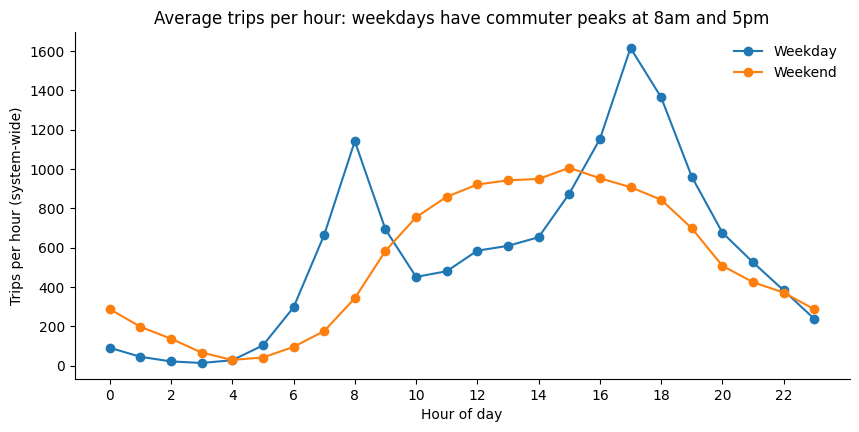

In [18]:
c = clean.assign(hod=clean["started_at"].dt.hour, weekend=clean["started_at"].dt.dayofweek >= 5)
n_days = c.groupby("weekend")["started_at"].apply(lambda s: s.dt.date.nunique())
by_hour = c.groupby(["weekend", "hod"]).size().div(n_days, level="weekend").unstack(0)

fig, ax = plt.subplots()
ax.plot(by_hour.index, by_hour[False], marker="o", label="Weekday")
ax.plot(by_hour.index, by_hour[True], marker="o", label="Weekend")
ax.set(title="Average trips per hour: weekdays have commuter peaks at 8am and 5pm",
       xlabel="Hour of day", ylabel="Trips per hour (system-wide)", xticks=range(0, 24, 2))
ax.legend(frameon=False)
plt.show()

### Chart 1b: Net bike loss by hour, residential vs. downtown station
The system-wide total hides the real problem. Residential stations **lose** bikes in the morning while downtown stations **gain** them, then the pattern reverses in the evening. We pick the two stations with the strongest opposite morning patterns.

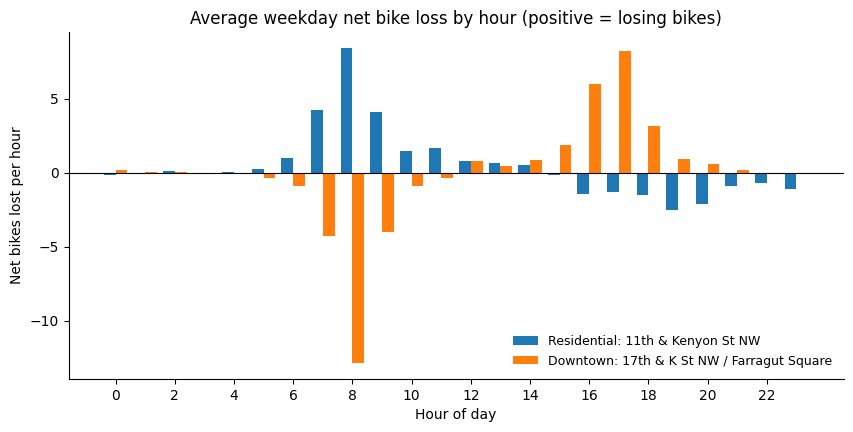

In [19]:
wk = sh[sh["hour"].dt.dayofweek < 5]
profile = wk.groupby(["station_id", wk["hour"].dt.hour])["net_loss"].mean().unstack()
morning = profile[[7, 8, 9]].mean(axis=1)
res_id, dt_id = morning.idxmax(), morning.idxmin()

fig, ax = plt.subplots()
ax.bar(profile.columns - 0.2, profile.loc[res_id], width=0.4, label=f"Residential: {names[res_id]}")
ax.bar(profile.columns + 0.2, profile.loc[dt_id], width=0.4, label=f"Downtown: {names[dt_id]}")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Average weekday net bike loss by hour (positive = losing bikes)",
       xlabel="Hour of day", ylabel="Net bikes lost per hour", xticks=range(0, 24, 2))
ax.legend(frameon=False, fontsize=9)
plt.show()

### Chart 2: Demand by day of week

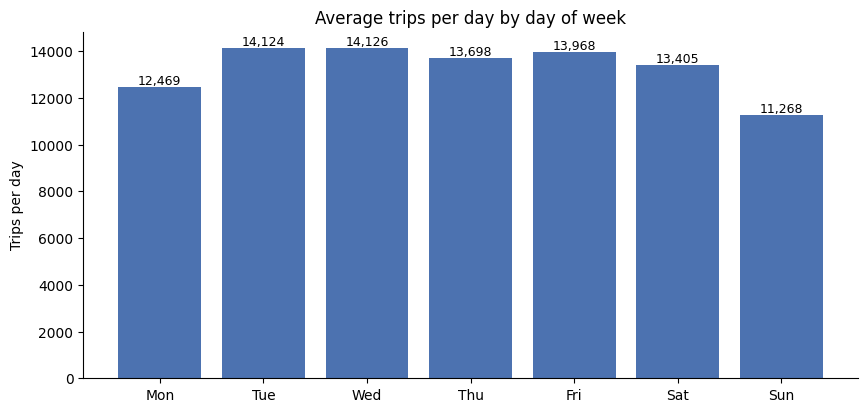

In [20]:
c["date"] = c["started_at"].dt.date
daily = c.groupby("date").size().rename("trips").reset_index()
daily["dow"] = pd.to_datetime(daily["date"]).dt.dayofweek
by_dow = daily.groupby("dow")["trips"].mean()

fig, ax = plt.subplots()
ax.bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], by_dow.values, color="#4C72B0")
ax.set(title="Average trips per day by day of week", ylabel="Trips per day")
for i, v in enumerate(by_dow.values):
    ax.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
plt.show()

### Chart 3: Demand by weather

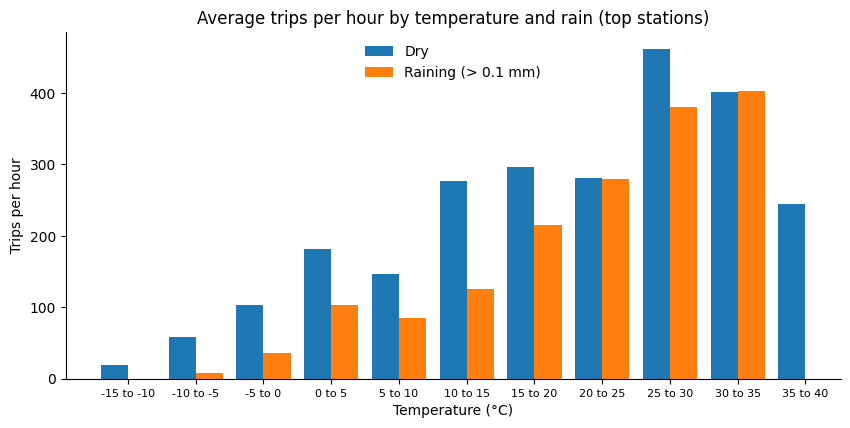

In [21]:
if HAVE_WEATHER:
    hourly = (sh.groupby("target_hour")
                .agg(trips=("departures", "sum"), temp_c=("temp_c", "first"), is_raining=("is_raining", "first"))
                .dropna())
    hourly["trips"] = hourly["trips"]  # departures from the modelled stations
    hourly["temp_bin"] = pd.cut(hourly["temp_c"], bins=range(-15, 41, 5))
    by_w = hourly.groupby(["temp_bin", "is_raining"], observed=True)["trips"].mean().unstack()

    fig, ax = plt.subplots()
    x = np.arange(len(by_w))
    ax.bar(x - 0.2, by_w.get(0), width=0.4, label="Dry")
    ax.bar(x + 0.2, by_w.get(1), width=0.4, label="Raining (> 0.1 mm)")
    ax.set_xticks(x, [f"{b.left} to {b.right}" for b in by_w.index], rotation=0, fontsize=8)
    ax.set(title="Average trips per hour by temperature and rain (top stations)",
           xlabel="Temperature (°C)", ylabel="Trips per hour")
    ax.legend(frameon=False)
    plt.show()
else:
    print("Weather data not loaded; rerun section 5 with internet access.")

### Chart 4: Demand by season

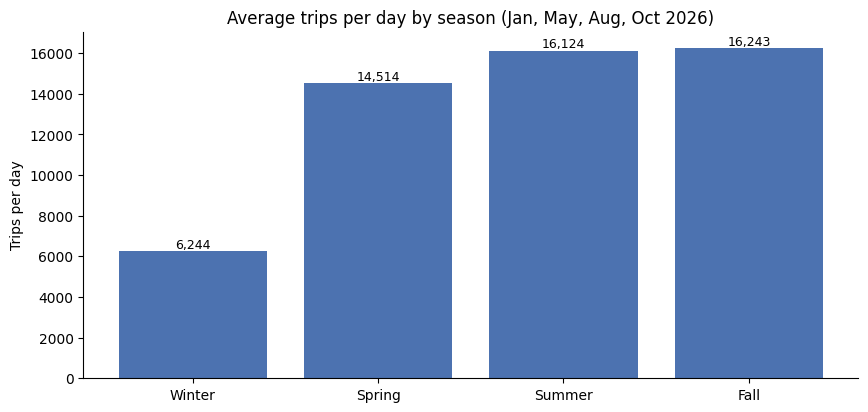

In [22]:
daily_s = c.assign(season=c["started_at"].dt.month.map(SEASON)).groupby(["season", "date"]).size()
by_season = daily_s.groupby("season").mean().reindex(["winter", "spring", "summer", "fall"])

fig, ax = plt.subplots()
ax.bar(by_season.index.str.title(), by_season.values, color="#4C72B0")
ax.set(title="Average trips per day by season (Jan, May, Aug, Oct 2026)", ylabel="Trips per day")
for i, v in enumerate(by_season.values):
    ax.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
plt.show()

## 8. Summary for the team
- The shared dataset is in `output/`, already split by day inside each month. **Do not shuffle** across splits.
- Every season appears in train, validation and test, so errors can be compared by `season` (Hypothesis 2).
- **Target:** `target_next_net_loss`. **Baseline:** `baseline_hist_avg` (Part 2 compares against it directly).
- Most station-hours have a target near 0; large values concentrate at a few stations during rush hours. That is why Part 4 should report a ranking metric (precision at top 10) in addition to MAE/RMSE.
- **For Part 3 (classification):** define "high loss" as the training set's 75th percentile of `target_next_net_loss`, and freeze that threshold before looking at val/test.

In [23]:
train = model_df[model_df["split"] == "train"]
print("target distribution (train):")
print(train["target_next_net_loss"].describe().round(2))
for q in (0.75, 0.90):
    print(f"{q:.0%} percentile of the target (train):", train["target_next_net_loss"].quantile(q))
# Note for Part 3: if the 75th percentile is 0, "high loss" = target > 0 is very broad;
# the 90th percentile gives a more meaningful "station is losing bikes fast" label.

target distribution (train):
count    134400.00
mean         -0.00
std           2.63
min         -29.00
25%          -1.00
50%           0.00
75%           1.00
max          24.00
Name: target_next_net_loss, dtype: float64
75% percentile of the target (train): 1.0
90% percentile of the target (train): 3.0
